# Kennedy Space Center (KSC)
## Hyperspectral Image Data Preprocessing

This notebook preprocesses the Kennedy Space Center (KSC)
hyperspectral dataset for deep learning based land-cover
classification.

### Processing Pipeline

KSC Hyperspectral Image
        ↓
Data Validation
        ↓
Spectral Standardization
        ↓
PCA Dimensionality Reduction
        ↓
9×9 Spatial-Spectral Patch Extraction
        ↓
Background Removal
        ↓
Stratified Train / Validation / Test Split
        ↓
Save Processed Dataset

### Final Model Input

Patch Size      : 9 × 9
PCA Components  : 30
Number Classes  : 13

In [1]:
import os
import random
import pickle

import numpy as np
import matplotlib.pyplot as plt

from scipy.io import loadmat

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import torch

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random Seed:", SEED)

Random Seed: 42


In [3]:
IMAGE_PATH = "/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC.mat"
GT_PATH = "/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC_gt.mat"

print("Image file exists:", os.path.exists(IMAGE_PATH))
print("Ground truth file exists:", os.path.exists(GT_PATH))

Image file exists: True
Ground truth file exists: True


In [4]:
CONFIG = {
    "DATASET": "KSC",

    "PATCH_SIZE": 9,
    "PCA_COMPONENTS": 30,

    "TRAIN_RATIO": 0.05,
    "VAL_RATIO": 0.05,
    "TEST_RATIO": 0.90,

    "NUM_CLASSES": 13,

    "SEED": 42,

    "OUTPUT_DIR": "/kaggle/working/processed_data_ksc"
}

os.makedirs(CONFIG["OUTPUT_DIR"], exist_ok=True)

print("Configuration:")
for key, value in CONFIG.items():
    print(f"{key}: {value}")

Configuration:
DATASET: KSC
PATCH_SIZE: 9
PCA_COMPONENTS: 30
TRAIN_RATIO: 0.05
VAL_RATIO: 0.05
TEST_RATIO: 0.9
NUM_CLASSES: 13
SEED: 42
OUTPUT_DIR: /kaggle/working/processed_data_ksc


In [5]:
image_mat = loadmat(IMAGE_PATH)
gt_mat = loadmat(GT_PATH)

print("KSC.mat variables:")
print(image_mat.keys())

print("\nKSC_gt.mat variables:")
print(gt_mat.keys())

KSC.mat variables:
dict_keys(['__header__', '__version__', '__globals__', 'KSC'])

KSC_gt.mat variables:
dict_keys(['__header__', '__version__', '__globals__', 'KSC_gt'])


In [6]:
image_mat = loadmat(IMAGE_PATH)
gt_mat = loadmat(GT_PATH)

print("KSC.mat variables:")
print(image_mat.keys())

print("\nKSC_gt.mat variables:")
print(gt_mat.keys())

KSC.mat variables:
dict_keys(['__header__', '__version__', '__globals__', 'KSC'])

KSC_gt.mat variables:
dict_keys(['__header__', '__version__', '__globals__', 'KSC_gt'])


In [7]:
if "KSC" in image_mat:
    image = image_mat["KSC"]
else:
    raise KeyError(
        "KSC variable was not found inside KSC.mat. "
        f"Available variables: {list(image_mat.keys())}"
    )


if "KSC_gt" in gt_mat:
    gt = gt_mat["KSC_gt"]
else:
    raise KeyError(
        "KSC_gt variable was not found inside KSC_gt.mat. "
        f"Available variables: {list(gt_mat.keys())}"
    )


print("Image loaded successfully.")
print("Ground truth loaded successfully.")

Image loaded successfully.
Ground truth loaded successfully.


In [8]:
print("Image shape:", image.shape)
print("Ground truth shape:", gt.shape)

print("Image dtype:", image.dtype)
print("GT dtype:", gt.dtype)

Image shape: (512, 614, 176)
Ground truth shape: (512, 614)
Image dtype: uint16
GT dtype: uint8


In [9]:
if image.shape[:2] != gt.shape:
    raise ValueError(
        f"Spatial dimension mismatch!\n"
        f"Image spatial shape: {image.shape[:2]}\n"
        f"GT shape: {gt.shape}"
    )

print("Spatial dimensions match.")

Spatial dimensions match.


In [10]:
image = image.astype(np.float32)
gt = gt.astype(np.int64)

print("Image dtype:", image.dtype)
print("GT dtype:", gt.dtype)

Image dtype: float32
GT dtype: int64


In [11]:
H, W, B = image.shape

print("=" * 50)
print("KSC DATASET INFORMATION")
print("=" * 50)

print("Height          :", H)
print("Width           :", W)
print("Spectral Bands  :", B)
print("Total Pixels    :", H * W)
print("GT Shape        :", gt.shape)

print("=" * 50)

KSC DATASET INFORMATION
Height          : 512
Width           : 614
Spectral Bands  : 176
Total Pixels    : 314368
GT Shape        : (512, 614)


In [12]:
print("Checking invalid values...\n")

image_nan = np.isnan(image).sum()
image_inf = np.isinf(image).sum()

gt_nan = np.isnan(gt).sum()
gt_inf = np.isinf(gt).sum()

print("Image NaN:", image_nan)
print("Image Inf:", image_inf)

print("GT NaN:", gt_nan)
print("GT Inf:", gt_inf)

Checking invalid values...

Image NaN: 0
Image Inf: 0
GT NaN: 0
GT Inf: 0


In [13]:
if image_nan > 0 or image_inf > 0:

    image = np.nan_to_num(
        image,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    print("Invalid image values replaced with 0.")

else:
    print("No invalid values found in image.")

No invalid values found in image.


In [14]:
print("Image statistics")

print("-" * 40)

print("Minimum :", np.min(image))
print("Maximum :", np.max(image))
print("Mean    :", np.mean(image))
print("Std     :", np.std(image))

Image statistics
----------------------------------------
Minimum : 0.0
Maximum : 65535.0
Mean    : 222.2799
Std     : 2900.2236


In [15]:
unique_classes, class_counts = np.unique(
    gt,
    return_counts=True
)

print("Ground Truth Classes")
print("-" * 40)

for cls, count in zip(unique_classes, class_counts):
    print(
        f"Class {int(cls):2d}: {int(count):6d} pixels"
    )

Ground Truth Classes
----------------------------------------
Class  0: 309157 pixels
Class  1:    761 pixels
Class  2:    243 pixels
Class  3:    256 pixels
Class  4:    252 pixels
Class  5:    161 pixels
Class  6:    229 pixels
Class  7:    105 pixels
Class  8:    431 pixels
Class  9:    520 pixels
Class 10:    404 pixels
Class 11:    419 pixels
Class 12:    503 pixels
Class 13:    927 pixels


In [16]:
CLASS_NAMES = {
    1: "Scrub",
    2: "Willow swamp",
    3: "CP hammock",
    4: "Slash pine",
    5: "Oak/Broadleaf",
    6: "Hardwood",
    7: "Swamp",
    8: "Graminoid marsh",
    9: "Spartina marsh",
    10: "Cattail marsh",
    11: "Salt marsh",
    12: "Mud flats",
    13: "Water"
}

print("KSC Classes")
print("-" * 50)

for class_id, name in CLASS_NAMES.items():
    count = np.sum(gt == class_id)

    print(
        f"{class_id:2d} | "
        f"{name:20s} | "
        f"{count:5d}"
    )

KSC Classes
--------------------------------------------------
 1 | Scrub                |   761
 2 | Willow swamp         |   243
 3 | CP hammock           |   256
 4 | Slash pine           |   252
 5 | Oak/Broadleaf        |   161
 6 | Hardwood             |   229
 7 | Swamp                |   105
 8 | Graminoid marsh      |   431
 9 | Spartina marsh       |   520
10 | Cattail marsh        |   404
11 | Salt marsh           |   419
12 | Mud flats            |   503
13 | Water                |   927


In [17]:
background_pixels = np.sum(gt == 0)
labeled_pixels = np.sum(gt > 0)

print("Total pixels      :", gt.size)
print("Background pixels :", background_pixels)
print("Labeled pixels    :", labeled_pixels)

Total pixels      : 314368
Background pixels : 309157
Labeled pixels    : 5211


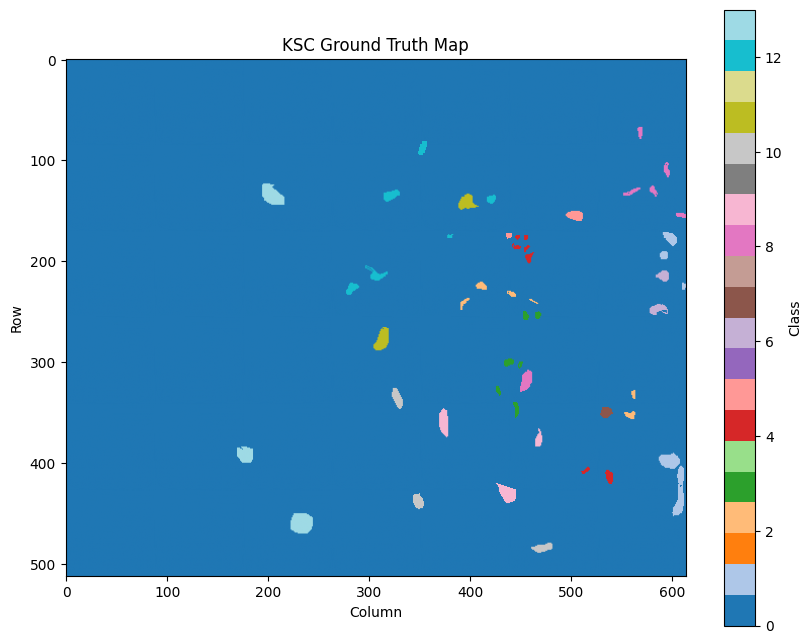

In [18]:
plt.figure(figsize=(10, 8))

plt.imshow(gt, cmap="tab20")

plt.title("KSC Ground Truth Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.colorbar(label="Class")

plt.show()

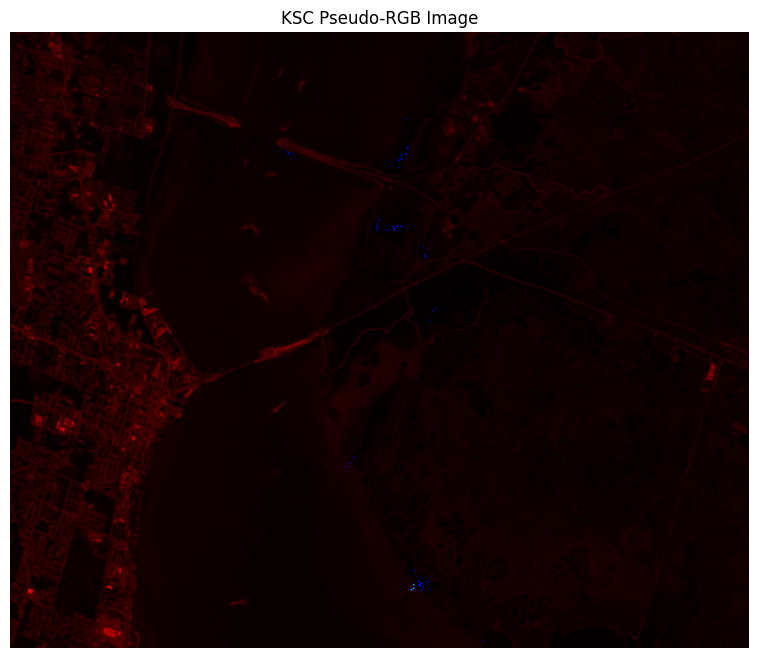

In [19]:
rgb_bands = [30, 60, 90]

rgb = image[:, :, rgb_bands]

rgb_display = np.zeros_like(rgb, dtype=np.float32)

for i in range(3):

    band = rgb[:, :, i]

    min_value = band.min()
    max_value = band.max()

    rgb_display[:, :, i] = (
        (band - min_value) /
        (max_value - min_value + 1e-8)
    )

plt.figure(figsize=(10, 8))

plt.imshow(rgb_display)

plt.title("KSC Pseudo-RGB Image")
plt.axis("off")

plt.show()

In [20]:
pixels = image.reshape(
    -1,
    B
)

print("Original image:", image.shape)
print("Flattened pixels:", pixels.shape)

Original image: (512, 614, 176)
Flattened pixels: (314368, 176)


In [21]:
scaler = StandardScaler()

pixels_scaled = scaler.fit_transform(pixels)

print("Scaled pixel matrix:", pixels_scaled.shape)

Scaled pixel matrix: (314368, 176)


In [22]:
print(
    "Mean after scaling:",
    np.mean(pixels_scaled)
)

print(
    "Std after scaling:",
    np.std(pixels_scaled)
)

Mean after scaling: 4.282374e-09
Std after scaling: 1.0000004


In [23]:
PCA_COMPONENTS = CONFIG["PCA_COMPONENTS"]

pca = PCA(
    n_components=PCA_COMPONENTS,
    random_state=CONFIG["SEED"]
)

pixels_pca = pca.fit_transform(
    pixels_scaled
)

print("Original spectral dimensions:", B)
print("Reduced spectral dimensions:", PCA_COMPONENTS)
print("PCA output shape:", pixels_pca.shape)

Original spectral dimensions: 176
Reduced spectral dimensions: 30
PCA output shape: (314368, 30)


In [24]:
explained_variance = pca.explained_variance_ratio_

print("PCA Explained Variance")
print("-" * 40)

for i, variance in enumerate(
    explained_variance,
    start=1
):
    print(
        f"PC {i:02d}: {variance:.6f}"
    )

print(
    "\nTotal explained variance:",
    explained_variance.sum()
)

PCA Explained Variance
----------------------------------------
PC 01: 0.287040
PC 02: 0.115630
PC 03: 0.109097
PC 04: 0.040175
PC 05: 0.024900
PC 06: 0.012190
PC 07: 0.009364
PC 08: 0.009103
PC 09: 0.008229
PC 10: 0.006871
PC 11: 0.006550
PC 12: 0.005987
PC 13: 0.005831
PC 14: 0.005796
PC 15: 0.005659
PC 16: 0.005581
PC 17: 0.005537
PC 18: 0.005295
PC 19: 0.005271
PC 20: 0.005207
PC 21: 0.005084
PC 22: 0.005016
PC 23: 0.004986
PC 24: 0.004873
PC 25: 0.004808
PC 26: 0.004800
PC 27: 0.004732
PC 28: 0.004723
PC 29: 0.004645
PC 30: 0.004615

Total explained variance: 0.72759616


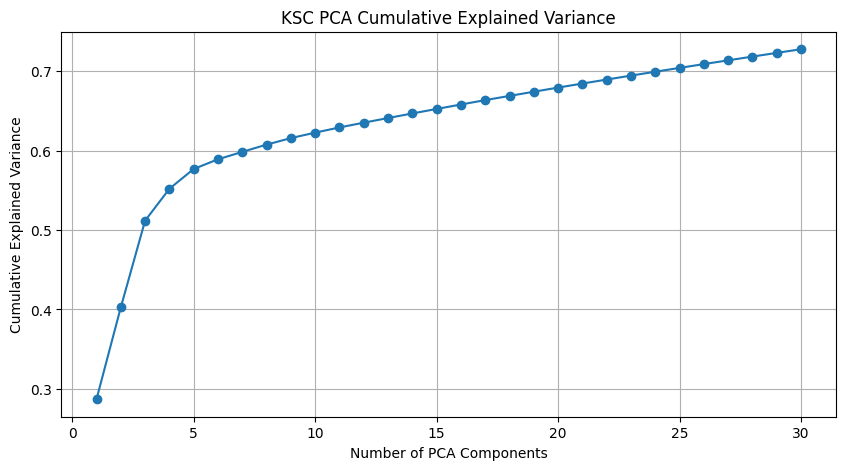

In [25]:
cumulative_variance = np.cumsum(
    explained_variance
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, PCA_COMPONENTS + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")

plt.title(
    "KSC PCA Cumulative Explained Variance"
)

plt.grid(True)

plt.show()

In [26]:
image_pca = pixels_pca.reshape(
    H,
    W,
    PCA_COMPONENTS
)

print("PCA image shape:", image_pca.shape)
del pixels
del pixels_scaled
del pixels_pca

print("Large intermediate arrays deleted.")

PCA image shape: (512, 614, 30)
Large intermediate arrays deleted.


In [27]:
import gc

gc.collect()

print("Garbage collection completed.")

Garbage collection completed.


In [28]:
def create_patches(image, labels, patch_size):

    margin = patch_size // 2

    padded = np.pad(
        image,
        (
            (margin, margin),
            (margin, margin),
            (0, 0)
        ),
        mode="reflect"
    )

    patches = []
    patch_labels = []

    rows, cols = labels.shape

    for i in range(rows):

        for j in range(cols):

            patch = padded[
                i:i + patch_size,
                j:j + patch_size,
                :
            ]

            patches.append(patch)
            patch_labels.append(labels[i, j])

    patches = np.asarray(
        patches,
        dtype=np.float32
    )

    patch_labels = np.asarray(
        patch_labels,
        dtype=np.int64
    )

    return patches, patch_labels

In [29]:
PATCH_SIZE = CONFIG["PATCH_SIZE"]

patches, labels = create_patches(
    image_pca,
    gt,
    PATCH_SIZE
)

print("Patches shape:", patches.shape)
print("Labels shape:", labels.shape)

Patches shape: (314368, 9, 9, 30)
Labels shape: (314368,)


In [30]:
labeled_mask = labels > 0

patches_labeled = patches[labeled_mask]
labels_labeled = labels[labeled_mask]

print("All patches     :", patches.shape)
print("Labeled patches :", patches_labeled.shape)

print("All labels      :", labels.shape)
print("Labeled labels  :", labels_labeled.shape)

All patches     : (314368, 9, 9, 30)
Labeled patches : (5211, 9, 9, 30)
All labels      : (314368,)
Labeled labels  : (5211,)


In [31]:
del patches
del labels
del labeled_mask
del image_pca

gc.collect()

print("Unused arrays deleted.")

Unused arrays deleted.


In [32]:
labels_labeled = labels_labeled - 1

print(
    "Minimum label:",
    labels_labeled.min()
)

print(
    "Maximum label:",
    labels_labeled.max()
)

Minimum label: 0
Maximum label: 12


In [33]:
unique, counts = np.unique(
    labels_labeled,
    return_counts=True
)

print("Final labeled dataset distribution")
print("-" * 55)

for cls, count in zip(unique, counts):

    original_class = int(cls) + 1

    print(
        f"Class {original_class:2d} | "
        f"{CLASS_NAMES[original_class]:20s} | "
        f"{int(count):5d}"
    )

Final labeled dataset distribution
-------------------------------------------------------
Class  1 | Scrub                |   761
Class  2 | Willow swamp         |   243
Class  3 | CP hammock           |   256
Class  4 | Slash pine           |   252
Class  5 | Oak/Broadleaf        |   161
Class  6 | Hardwood             |   229
Class  7 | Swamp                |   105
Class  8 | Graminoid marsh      |   431
Class  9 | Spartina marsh       |   520
Class 10 | Cattail marsh        |   404
Class 11 | Salt marsh           |   419
Class 12 | Mud flats            |   503
Class 13 | Water                |   927


In [34]:
X_train, X_temp, y_train, y_temp = train_test_split(
    patches_labeled,
    labels_labeled,

    train_size=CONFIG["TRAIN_RATIO"],

    random_state=CONFIG["SEED"],

    stratify=labels_labeled
)

print("Training set created.")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

Training set created.
X_train: (260, 9, 9, 30)
y_train: (260,)


In [35]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,

    train_size=CONFIG["VAL_RATIO"] /
               (CONFIG["VAL_RATIO"] + CONFIG["TEST_RATIO"]),

    random_state=CONFIG["SEED"],

    stratify=y_temp
)

print("Validation and test sets created.")

Validation and test sets created.


In [36]:
del X_temp
del y_temp
del patches_labeled
del labels_labeled

gc.collect()

print("Temporary arrays deleted.")

Temporary arrays deleted.


In [37]:
print("=" * 60)
print("FINAL DATASET SHAPES")
print("=" * 60)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print()

print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)

print()

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("=" * 60)

FINAL DATASET SHAPES
X_train: (260, 9, 9, 30)
y_train: (260,)

X_val  : (260, 9, 9, 30)
y_val  : (260,)

X_test : (4691, 9, 9, 30)
y_test : (4691,)


In [38]:
total_samples = (
    len(y_train)
    + len(y_val)
    + len(y_test)
)

print("Train samples      :", len(y_train))
print("Validation samples :", len(y_val))
print("Test samples       :", len(y_test))

print("\nTotal samples:", total_samples)

Train samples      : 260
Validation samples : 260
Test samples       : 4691

Total samples: 5211


In [39]:
total = len(y_train) + len(y_val) + len(y_test)

train_percentage = len(y_train) / total * 100
val_percentage = len(y_val) / total * 100
test_percentage = len(y_test) / total * 100

print(f"Train      : {train_percentage:.2f}%")
print(f"Validation : {val_percentage:.2f}%")
print(f"Test       : {test_percentage:.2f}%")

Train      : 4.99%
Validation : 4.99%
Test       : 90.02%


In [40]:
def show_class_distribution(labels, name):

    print(f"\n{name}")
    print("-" * 50)

    unique, counts = np.unique(
        labels,
        return_counts=True
    )

    for cls, count in zip(unique, counts):

        class_id = int(cls) + 1

        print(
            f"Class {class_id:2d} | "
            f"{CLASS_NAMES[class_id]:20s} | "
            f"{int(count):4d}"
        )


show_class_distribution(
    y_train,
    "TRAIN"
)


TRAIN
--------------------------------------------------
Class  1 | Scrub                |   38
Class  2 | Willow swamp         |   12
Class  3 | CP hammock           |   13
Class  4 | Slash pine           |   13
Class  5 | Oak/Broadleaf        |    8
Class  6 | Hardwood             |   11
Class  7 | Swamp                |    5
Class  8 | Graminoid marsh      |   22
Class  9 | Spartina marsh       |   26
Class 10 | Cattail marsh        |   20
Class 11 | Salt marsh           |   21
Class 12 | Mud flats            |   25
Class 13 | Water                |   46


In [41]:
show_class_distribution(
    y_val,
    "VALIDATION"
)
show_class_distribution(
    y_test,
    "TEST"
)


VALIDATION
--------------------------------------------------
Class  1 | Scrub                |   38
Class  2 | Willow swamp         |   12
Class  3 | CP hammock           |   13
Class  4 | Slash pine           |   13
Class  5 | Oak/Broadleaf        |    8
Class  6 | Hardwood             |   11
Class  7 | Swamp                |    5
Class  8 | Graminoid marsh      |   22
Class  9 | Spartina marsh       |   26
Class 10 | Cattail marsh        |   20
Class 11 | Salt marsh           |   21
Class 12 | Mud flats            |   25
Class 13 | Water                |   46

TEST
--------------------------------------------------
Class  1 | Scrub                |  685
Class  2 | Willow swamp         |  219
Class  3 | CP hammock           |  230
Class  4 | Slash pine           |  226
Class  5 | Oak/Broadleaf        |  145
Class  6 | Hardwood             |  207
Class  7 | Swamp                |   95
Class  8 | Graminoid marsh      |  387
Class  9 | Spartina marsh       |  468
Class 10 | Cattail mar

In [42]:
expected_classes = set(
    range(CONFIG["NUM_CLASSES"])
)

train_classes = set(np.unique(y_train))
val_classes = set(np.unique(y_val))
test_classes = set(np.unique(y_test))

print("Expected classes:", expected_classes)

print(
    "Missing from train:",
    expected_classes - train_classes
)

print(
    "Missing from validation:",
    expected_classes - val_classes
)

print(
    "Missing from test:",
    expected_classes - test_classes
)

Expected classes: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12}
Missing from train: set()
Missing from validation: set()
Missing from test: set()


In [43]:
sample_index = 0

sample_patch = X_train[sample_index]
sample_label = y_train[sample_index]

print("Sample patch shape:", sample_patch.shape)
print("Encoded label:", sample_label)
print(
    "Original class:",
    sample_label + 1
)
print(
    "Class name:",
    CLASS_NAMES[sample_label + 1]
)

Sample patch shape: (9, 9, 30)
Encoded label: 0
Original class: 1
Class name: Scrub


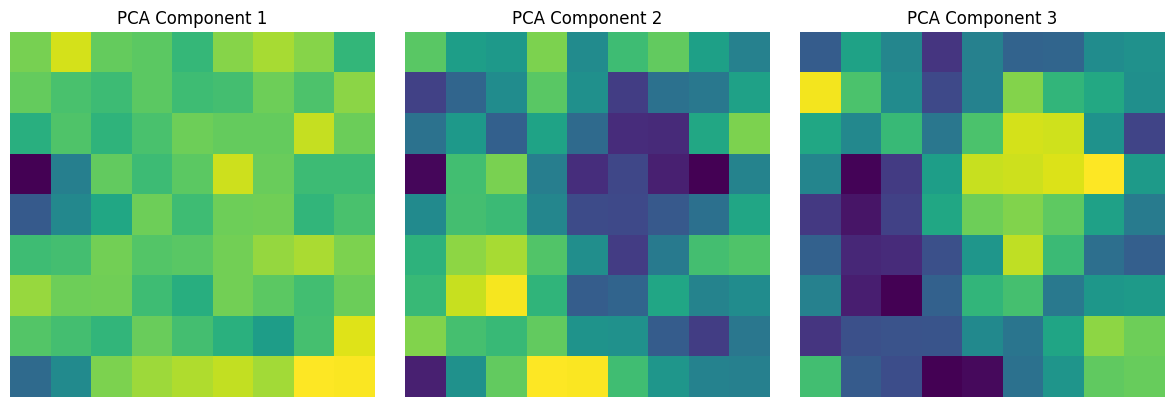

In [44]:
plt.figure(figsize=(12, 4))

for i in range(3):

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        sample_patch[:, :, i]
    )

    plt.title(
        f"PCA Component {i + 1}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [45]:
output_dir = CONFIG["OUTPUT_DIR"]

np.savez_compressed(
    os.path.join(
        output_dir,
        "train.npz"
    ),
    X=X_train,
    y=y_train
)

print("train.npz saved.")

train.npz saved.


In [46]:
np.savez_compressed(
    os.path.join(
        output_dir,
        "validation.npz"
    ),
    X=X_val,
    y=y_val
)

print("validation.npz saved.")

validation.npz saved.


In [47]:
np.savez_compressed(
    os.path.join(
        output_dir,
        "test.npz"
    ),
    X=X_test,
    y=y_test
)

print("test.npz saved.")

test.npz saved.


In [48]:
scaler_path = os.path.join(
    output_dir,
    "scaler.pkl"
)

with open(
    scaler_path,
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )

print("Scaler saved:")
print(scaler_path)

Scaler saved:
/kaggle/working/processed_data_ksc/scaler.pkl


In [49]:
pca_path = os.path.join(
    output_dir,
    "pca.pkl"
)

with open(
    pca_path,
    "wb"
) as f:

    pickle.dump(
        pca,
        f
    )

print("PCA saved:")
print(pca_path)

PCA saved:
/kaggle/working/processed_data_ksc/pca.pkl


In [50]:
config_path = os.path.join(
    output_dir,
    "config.pkl"
)

with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        CONFIG,
        f
    )

print("Configuration saved.")

Configuration saved.


In [51]:
train_loaded = np.load(
    os.path.join(
        output_dir,
        "train.npz"
    )
)

val_loaded = np.load(
    os.path.join(
        output_dir,
        "validation.npz"
    )
)

test_loaded = np.load(
    os.path.join(
        output_dir,
        "test.npz"
    )
)

print("Train:", train_loaded["X"].shape, train_loaded["y"].shape)
print("Val  :", val_loaded["X"].shape, val_loaded["y"].shape)
print("Test :", test_loaded["X"].shape, test_loaded["y"].shape)

Train: (260, 9, 9, 30) (260,)
Val  : (260, 9, 9, 30) (260,)
Test : (4691, 9, 9, 30) (4691,)


In [52]:
assert train_loaded["X"].ndim == 4
assert val_loaded["X"].ndim == 4
assert test_loaded["X"].ndim == 4

assert train_loaded["X"].shape[1:] == (9, 9, 30)
assert val_loaded["X"].shape[1:] == (9, 9, 30)
assert test_loaded["X"].shape[1:] == (9, 9, 30)

assert train_loaded["y"].min() >= 0
assert train_loaded["y"].max() < 13

assert val_loaded["y"].min() >= 0
assert val_loaded["y"].max() < 13

assert test_loaded["y"].min() >= 0
assert test_loaded["y"].max() < 13

print("All integrity checks passed.")

All integrity checks passed.


In [53]:
print("\n" + "=" * 70)
print("KSC PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Dataset              : {CONFIG['DATASET']}")
print(f"Original Image       : {H} × {W} × {B}")
print(f"PCA Components       : {CONFIG['PCA_COMPONENTS']}")
print(f"Patch Size           : {CONFIG['PATCH_SIZE']} × {CONFIG['PATCH_SIZE']}")
print(f"Final Patch          : {CONFIG['PATCH_SIZE']} × {CONFIG['PATCH_SIZE']} × {CONFIG['PCA_COMPONENTS']}")
print(f"Number of Classes    : {CONFIG['NUM_CLASSES']}")

print()
print(f"Train Samples        : {len(y_train)}")
print(f"Validation Samples   : {len(y_val)}")
print(f"Test Samples         : {len(y_test)}")

print()
print("Train Shape          :", X_train.shape)
print("Validation Shape     :", X_val.shape)
print("Test Shape           :", X_test.shape)

print()
print("Output Directory:")
print(CONFIG["OUTPUT_DIR"])

print("=" * 70)


KSC PREPROCESSING COMPLETED SUCCESSFULLY
Dataset              : KSC
Original Image       : 512 × 614 × 176
PCA Components       : 30
Patch Size           : 9 × 9
Final Patch          : 9 × 9 × 30
Number of Classes    : 13

Train Samples        : 260
Validation Samples   : 260
Test Samples         : 4691

Train Shape          : (260, 9, 9, 30)
Validation Shape     : (260, 9, 9, 30)
Test Shape           : (4691, 9, 9, 30)

Output Directory:
/kaggle/working/processed_data_ksc


In [54]:
print("Saved files:")
print("-" * 40)

for file in sorted(os.listdir(CONFIG["OUTPUT_DIR"])):
    
    path = os.path.join(
        CONFIG["OUTPUT_DIR"],
        file
    )

    size_mb = os.path.getsize(path) / (1024 ** 2)

    print(
        f"{file:25s} "
        f"{size_mb:.2f} MB"
    )

Saved files:
----------------------------------------
config.pkl                0.00 MB
pca.pkl                   0.02 MB
scaler.pkl                0.00 MB
test.npz                  40.01 MB
train.npz                 2.26 MB
validation.npz            2.21 MB
